# Practical 5: KNN on the Diabetes Dataset

**Aim:** Implement KNN on diabetes.csv and compute the confusion matrix, accuracy, error rate, precision and recall.

## Setup: libraries and dataset loader

The loader tries Kaggle first. If the download fails, it asks you to upload the CSV (a file picker appears). You can also drag the CSV into the Colab Files panel before running.

In [1]:
!pip install -q kagglehub

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def get_dataset(kaggle_handle, filename, fallback_url=None, fallback_kwargs=None, **read_kwargs):
    """Load a CSV. Order: (1) file already in the Colab workspace, (2) Kaggle via kagglehub,
    (3) optional public fallback URL, (4) manual upload prompt."""
    # 1. already present (e.g. you dragged it into the Colab Files panel)
    for p in [filename, f"/content/{filename}"]:
        if os.path.exists(p):
            print("Using existing file:", p)
            return pd.read_csv(p, **read_kwargs)
    # 2. Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download(kaggle_handle)
        hits = glob.glob(os.path.join(folder, "**", filename), recursive=True)
        if hits:
            print("Downloaded from Kaggle:", hits[0])
            return pd.read_csv(hits[0], **read_kwargs)
        print("Kaggle download worked but", filename, "was not found inside it.")
    except Exception as e:
        print("Kaggle download failed:", type(e).__name__, str(e)[:200])
    # 3. public fallback
    if fallback_url:
        try:
            print("Trying fallback URL ...")
            return pd.read_csv(fallback_url, **(fallback_kwargs or read_kwargs))
        except Exception as e:
            print("Fallback failed:", type(e).__name__)
    # 4. manual upload
    print(f"Please upload {filename} (download it from https://www.kaggle.com/datasets/{kaggle_handle})")
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    return pd.read_csv(name, **read_kwargs)

print("Setup complete")

Setup complete


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
PIMA_COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
# Kaggle first; if that fails, the public Pima copy on GitHub is used (it has no header row, so names are supplied)
df5 = get_dataset("abdallamahgoub/diabetes", "diabetes.csv",
                  fallback_url="https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv",
                  fallback_kwargs=dict(header=None, names=PIMA_COLS))
print(df5.shape)
df5.head()

100%|██████████| 8.89k/8.89k [00:00<00:00, 13.8MB/s]

Extracting files...
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/abdallamahgoub/diabetes/versions/1/diabetes.csv
(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Pre-processing: zeros are impossible in these columns, so treat them as missing and use the median
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df5[cols] = df5[cols].replace(0, np.nan)
df5[cols] = df5[cols].fillna(df5[cols].median())

X5 = df5.drop(columns=["Outcome"])
y5 = df5["Outcome"]
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.2, random_state=42, stratify=y5)
sc5 = StandardScaler()
X5_train = sc5.fit_transform(X5_train)
X5_test = sc5.transform(X5_test)

knn5 = KNeighborsClassifier(n_neighbors=5, metric="euclidean").fit(X5_train, y5_train)
y5_pred = knn5.predict(X5_test)

Confusion Matrix:
 [[83 17]
 [21 33]]
TP=33, TN=83, FP=17, FN=21
Accuracy   : 0.7532
Error Rate : 0.2468
Precision  : 0.6600
Recall     : 0.6111


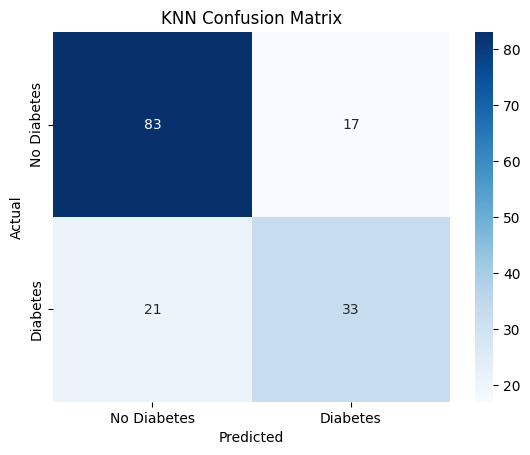

In [5]:
cm5 = confusion_matrix(y5_test, y5_pred)
tn, fp, fn, tp = cm5.ravel()
accuracy = accuracy_score(y5_test, y5_pred)
print("Confusion Matrix:\n", cm5)
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Error Rate : {1 - accuracy:.4f}")
print(f"Precision  : {precision_score(y5_test, y5_pred):.4f}")
print(f"Recall     : {recall_score(y5_test, y5_pred):.4f}")

sns.heatmap(cm5, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("KNN Confusion Matrix"); plt.show()

**Final output**

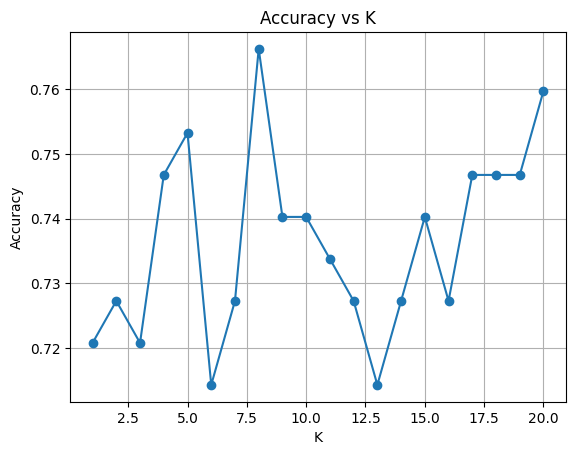

Best K: 8


In [6]:
ks = range(1, 21)
scores = [accuracy_score(y5_test, KNeighborsClassifier(n_neighbors=k).fit(X5_train, y5_train).predict(X5_test)) for k in ks]
plt.plot(ks, scores, marker="o"); plt.xlabel("K"); plt.ylabel("Accuracy"); plt.grid(True)
plt.title("Accuracy vs K"); plt.show()
print("Best K:", list(ks)[int(np.argmax(scores))])

**Conclusion (Practical 5):** KNN performance depends on K and on feature scaling. In medical screening, recall matters most because a missed patient is worse than a false alarm.